In [3]:

from pathlib import Path

file_path = Path.home() / "Desktop" / "Business-Analytics-Portfolio" / "01_Ecommerce_Analytics" / "raw" / "Online Retail.xlsx"

print("File exists:", file_path.exists())
print("File location:", file_path)


File exists: True
File location: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/raw/Online Retail.xlsx


In [5]:

import pandas as pd

# Load the original retail dataset
df = pd.read_excel(file_path)

# Display the first five records
display(df.head())


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:

# 1. Check the number of rows and columns
print("Dataset shape:", df.shape)

# 2. Check the column names
print("\nColumn names:")
print(df.columns.tolist())

# 3. Check data types and non-missing values
print("\nDataset information:")
df.info()


Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [12]:

# Summarise missing values
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

display(missing_summary)


,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


In [14]:

from pathlib import Path

# Locate your project folder automatically
project_path = file_path.parents[2]
reports_path = project_path / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

# Save the missing-value summary
missing_summary.to_csv(
    reports_path / "initial_missing_values_report.csv"
)

# Create a written inspection report
report = f"""
ECOMMERCE DATASET: INITIAL INSPECTION REPORT

Dataset: UCI Online Retail
Total records: {df.shape[0]:,}
Total columns: {df.shape[1]}

COLUMNS:
{", ".join(df.columns)}

MISSING VALUES:
{missing_summary.to_string()}

INITIAL OBSERVATIONS:
1. CustomerID has missing values requiring investigation.
2. Description has a small number of missing values.
3. InvoiceDate is already stored as a datetime type.
4. Transaction-level records need further quality checks.

No records have been removed or modified.
"""

with open(
    reports_path / "initial_data_inspection_report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("Reports saved to:", reports_path)
print("Files created:")
print("- initial_missing_values_report.csv")
print("- initial_data_inspection_report.txt")


Reports saved to: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports
Files created:
- initial_missing_values_report.csv
- initial_data_inspection_report.txt


In [16]:

# Check for duplicate transaction rows
duplicate_count = df.duplicated().sum()

# Identify cancelled invoices
cancelled_mask = df["InvoiceNo"].astype(str).str.startswith("C")

# Check unusual quantities and prices
negative_quantity_count = (df["Quantity"] < 0).sum()
zero_quantity_count = (df["Quantity"] == 0).sum()
negative_price_count = (df["UnitPrice"] < 0).sum()
zero_price_count = (df["UnitPrice"] == 0).sum()

# Check the date range and unique values
print("Duplicate rows:", duplicate_count)
print("Cancelled invoice rows:", cancelled_mask.sum())
print("Negative quantities:", negative_quantity_count)
print("Zero quantities:", zero_quantity_count)
print("Negative unit prices:", negative_price_count)
print("Zero unit prices:", zero_price_count)

print("\nDate range:")
print("Earliest:", df["InvoiceDate"].min())
print("Latest:", df["InvoiceDate"].max())

print("\nUnique invoices:", df["InvoiceNo"].nunique())
print("Unique product codes:", df["StockCode"].nunique())
print("Unique customers:", df["CustomerID"].nunique())


Duplicate rows: 5268
Cancelled invoice rows: 9288
Negative quantities: 10624
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2515

Date range:
Earliest: 2010-12-01 08:26:00
Latest: 2011-12-09 12:50:00

Unique invoices: 25900
Unique product codes: 4070
Unique customers: 4372


In [18]:

# Show examples of exact duplicate rows
print("EXAMPLES OF DUPLICATE ROWS")
display(
    df[df.duplicated(keep=False)]
    .sort_values(["InvoiceNo", "StockCode"])
    .head(10)
)

# Show examples of cancelled invoices
print("\nEXAMPLES OF CANCELLED INVOICE LINES")
display(
    df[cancelled_mask]
    [["InvoiceNo", "StockCode", "Description",
      "Quantity", "UnitPrice", "CustomerID"]]
    .head(10)
)

# Inspect negative unit prices
print("\nRECORDS WITH NEGATIVE UNIT PRICES")
display(df[df["UnitPrice"] < 0])

# Inspect zero-price records
print("\nEXAMPLES OF ZERO-PRICE RECORDS")
display(
    df[df["UnitPrice"] == 0]
    [["InvoiceNo", "StockCode", "Description",
      "Quantity", "UnitPrice", "CustomerID"]]
    .head(10)
)


EXAMPLES OF DUPLICATE ROWS


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom



EXAMPLES OF CANCELLED INVOICE LINES


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
141,C536379,D,Discount,-1,27.50,14527.0
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,4.65,15311.0
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,1.65,17548.0
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,0.29,17548.0
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,0.29,17548.0
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,0.29,17548.0
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,3.45,17548.0
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,1.65,17548.0
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,1.65,17548.0
939,C536506,22960,JAM MAKING SET WITH JARS,-6,4.25,17897.0



RECORDS WITH NEGATIVE UNIT PRICES


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom



EXAMPLES OF ZERO-PRICE RECORDS


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID
622,536414,22139,NaN,56,0.0,NaN
1970,536545,21134,NaN,1,0.0,NaN
1971,536546,22145,NaN,1,0.0,NaN
1972,536547,37509,NaN,1,0.0,NaN
1987,536549,85226A,NaN,1,0.0,NaN
1988,536550,85044,NaN,1,0.0,NaN
2024,536552,20950,NaN,1,0.0,NaN
2025,536553,37461,NaN,3,0.0,NaN
2026,536554,84670,NaN,23,0.0,NaN
2406,536589,21777,NaN,-10,0.0,NaN


In [20]:

# Compare cancellation status with quantity sign
quality_comparison = pd.crosstab(
    cancelled_mask.rename("Cancelled invoice"),
    (df["Quantity"] < 0).rename("Negative quantity"),
    margins=True
)

display(quality_comparison)

# Check duplicate rows against cancellation status
print(
    "Duplicate rows with cancellation invoice prefix:",
    (df.duplicated(keep=False) & cancelled_mask).sum()
)


Negative quantity,False,True,All
Cancelled invoice,,,
False,531285,1336,532621
True,0,9288,9288
All,531285,10624,541909


Duplicate rows with cancellation invoice prefix: 69


In [22]:

# 1. Negative quantities without a cancelled-invoice prefix
negative_not_cancelled = df[
    (df["Quantity"] < 0) & (~cancelled_mask)
]

print("Negative quantities without cancellation prefix:",
      len(negative_not_cancelled))

display(
    negative_not_cancelled[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
    ].head(20)
)

# 2. Summarise zero-price records
zero_price = df[df["UnitPrice"] == 0]

print("\nZero-price rows:", len(zero_price))
print("Zero-price rows with missing descriptions:",
      zero_price["Description"].isna().sum())
print("Zero-price rows with missing customer IDs:",
      zero_price["CustomerID"].isna().sum())

print("\nMost frequent descriptions among zero-price rows:")
display(
    zero_price["Description"]
    .fillna("[Missing description]")
    .value_counts()
    .head(15)
    .rename_axis("Description")
    .reset_index(name="Rows")
)

print("\nMost frequent stock codes among zero-price rows:")
display(
    zero_price["StockCode"]
    .value_counts()
    .head(15)
    .rename_axis("StockCode")
    .reset_index(name="Rows")
)

# 3. Check whether the two bad-debt adjustments are the only
# negative-price records, and inspect their transaction types.
print("\nNegative-price records:")
display(df[df["UnitPrice"] < 0])


Negative quantities without cancellation prefix: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom



Zero-price rows: 2515
Zero-price rows with missing descriptions: 1454
Zero-price rows with missing customer IDs: 2475

Most frequent descriptions among zero-price rows:


,Description,Rows
0,[Missing description],1454
1,check,159
2,?,47
3,damages,45
4,damaged,43
5,found,25
6,sold as set on dotcom,20
7,adjustment,16
8,Damaged,14
9,"Unsaleable, destroyed.",9



Most frequent stock codes among zero-price rows:


,StockCode,Rows
0,23084,16
1,35965,13
2,20713,11
3,22501,10
4,22627,9
5,22084,9
6,22676,9
7,21116,8
8,82583,8
9,22683,8



Negative-price records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [24]:

# STEP 3: Clean the sales dataset

# Keep the original df unchanged.
df_working = df.copy()

# Record the starting number of rows.
starting_rows = len(df_working)

# Rule 1: Remove exact duplicate rows.
df_working = df_working.drop_duplicates().copy()
after_duplicates = len(df_working)

# Rule 2: Exclude cancelled invoices (invoice numbers starting with C).
cancelled = df_working["InvoiceNo"].astype(str).str.startswith("C")
df_working = df_working.loc[~cancelled].copy()
after_cancellations = len(df_working)

# Rule 3: Keep only positive quantities.
positive_quantity = df_working["Quantity"] > 0
df_working = df_working.loc[positive_quantity].copy()
after_quantity_filter = len(df_working)

# Rule 4: Keep only positive unit prices.
positive_price = df_working["UnitPrice"] > 0
df_clean = df_working.loc[positive_price].copy()

# Calculate line-level sales value.
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Convert CustomerID to a nullable integer identifier.
# Missing customer IDs remain missing rather than becoming zero.
df_clean["CustomerID"] = df_clean["CustomerID"].astype("Int64")

# Make identifier columns consistent.
df_clean["InvoiceNo"] = df_clean["InvoiceNo"].astype(str)
df_clean["StockCode"] = df_clean["StockCode"].astype(str)

# Show the effect of each cleaning rule.
cleaning_summary = pd.DataFrame({
    "Stage": [
        "Original dataset",
        "After removing exact duplicates",
        "After excluding cancelled invoices",
        "After requiring positive quantities",
        "Final sales dataset"
    ],
    "Rows remaining": [
        starting_rows,
        after_duplicates,
        after_cancellations,
        after_quantity_filter,
        len(df_clean)
    ]
})

cleaning_summary["Rows removed at stage"] = (
    cleaning_summary["Rows remaining"].shift(1)
    - cleaning_summary["Rows remaining"]
)
cleaning_summary.loc[0, "Rows removed at stage"] = 0

display(cleaning_summary)

print("Final dataset shape:", df_clean.shape)
print("Missing customer IDs:", df_clean["CustomerID"].isna().sum())
print("Missing descriptions:", df_clean["Description"].isna().sum())
print("Non-positive quantities:", (df_clean["Quantity"] <= 0).sum())
print("Non-positive unit prices:", (df_clean["UnitPrice"] <= 0).sum())
print("Revenue calculation check:",
      (df_clean["Revenue"] ==
       df_clean["Quantity"] * df_clean["UnitPrice"]).all())

display(df_clean.head())


,Stage,Rows remaining,Rows removed at stage
0,Original dataset,541909,0.0
1,After removing exact duplicates,536641,5268.0
2,After excluding cancelled invoices,527390,9251.0
3,After requiring positive quantities,526054,1336.0
4,Final sales dataset,524878,1176.0


Final dataset shape: (524878, 9)
Missing customer IDs: 132186
Missing descriptions: 0
Non-positive quantities: 0
Non-positive unit prices: 0
Revenue calculation check: True


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [26]:

# STEP 4: Save the cleaned dataset and cleaning documentation

from pathlib import Path

project_path = file_path.parents[2]
processed_path = project_path / "data" / "processed"
reports_path = project_path / "reports"

processed_path.mkdir(parents=True, exist_ok=True)
reports_path.mkdir(parents=True, exist_ok=True)

# Save the cleaned transaction data.
cleaned_file = processed_path / "online_retail_cleaned.csv"
df_clean.to_csv(cleaned_file, index=False)

# Save the cleaning summary.
summary_file = reports_path / "cleaning_summary.csv"
cleaning_summary.to_csv(summary_file, index=False)

# Create a text report documenting the cleaning decisions.
report = f"""
ONLINE RETAIL DATA CLEANING REPORT
==================================

Dataset source: UCI Online Retail
Source file: Online Retail.xlsx

1. ORIGINAL DATA
Rows: {len(df):,}
Columns: {df.shape[1]}

2. CLEANING RULES APPLIED
- Removed exact duplicate rows.
- Excluded invoice numbers beginning with C.
- Excluded rows with zero or negative quantities.
- Excluded rows with zero or negative unit prices.
- Retained missing CustomerID values for overall sales analysis.
- Added Revenue = Quantity * UnitPrice.
- Converted CustomerID to a nullable integer identifier.
- Converted InvoiceNo and StockCode to text identifiers.

3. ROW COUNTS
{cleaning_summary.to_string(index=False)}

4. FINAL DATASET
Rows: {len(df_clean):,}
Columns: {df_clean.shape[1]}
Missing CustomerID values: {df_clean["CustomerID"].isna().sum():,}
Missing descriptions: {df_clean["Description"].isna().sum():,}
Non-positive quantities: {(df_clean["Quantity"] <= 0).sum():,}
Non-positive unit prices: {(df_clean["UnitPrice"] <= 0).sum():,}
Total line-level sales value: {df_clean["Revenue"].sum():,.2f}

5. LIMITATIONS
- Missing CustomerID values limit customer-level analysis.
- Excluded transactions may include returns, adjustments, free items,
  or other non-standard business activity.
- The cleaned dataset represents positive-quantity, positive-price
  sales lines under the rules above. It is not a complete accounting
  ledger and should not automatically be interpreted as profit.
- Exact duplicate removal assumes fully identical rows are duplicated
  records; the original source file remains unchanged.

6. OUTPUT FILES
- data/processed/online_retail_cleaned.csv
- reports/cleaning_summary.csv
- reports/data_cleaning_report.txt
"""

report_file = reports_path / "data_cleaning_report.txt"
report_file.write_text(report, encoding="utf-8")

print("Files saved successfully:")
print(cleaned_file)
print(summary_file)
print(report_file)

print("\nFile sizes:")
for path in [cleaned_file, summary_file, report_file]:
    print(f"{path.name}: {path.stat().st_size:,} bytes")


Files saved successfully:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/data/processed/online_retail_cleaned.csv
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/cleaning_summary.csv
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/data_cleaning_report.txt

File sizes:
online_retail_cleaned.csv: 49,553,474 bytes
cleaning_summary.csv: 250 bytes
data_cleaning_report.txt: 1,910 bytes


In [28]:

# STEP 5: Calculate core business KPIs

# 1. Overall sales KPIs
total_sales = df_clean["Revenue"].sum()
total_quantity = df_clean["Quantity"].sum()
total_invoices = df_clean["InvoiceNo"].nunique()
unique_products = df_clean["StockCode"].nunique()
known_customers = df_clean["CustomerID"].nunique()
average_order_value = total_sales / total_invoices

missing_customer_pct = (
    df_clean["CustomerID"].isna().mean() * 100
)

kpis = pd.DataFrame({
    "KPI": [
        "Total sales value",
        "Total quantity sold",
        "Unique invoices",
        "Unique product codes",
        "Customers with an ID",
        "Average order value",
        "Rows missing CustomerID (%)"
    ],
    "Value": [
        round(total_sales, 2),
        int(total_quantity),
        int(total_invoices),
        int(unique_products),
        int(known_customers),
        round(average_order_value, 2),
        round(missing_customer_pct, 2)
    ]
})

display(kpis)

# 2. Monthly sales trend
monthly_sales = (
    df_clean.assign(
        Month=df_clean["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month", as_index=False)
    .agg(
        Sales=("Revenue", "sum"),
        Quantity_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .sort_values("Month")
)

monthly_sales["Sales"] = monthly_sales["Sales"].round(2)

print("\nMONTHLY SALES TREND")
display(monthly_sales)

# 3. Save the KPI and monthly analysis outputs
reports_path = file_path.parents[2] / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

kpis.to_csv(reports_path / "core_business_kpis.csv", index=False)
monthly_sales.to_csv(reports_path / "monthly_sales_trend.csv", index=False)

print("\nSaved:")
print(reports_path / "core_business_kpis.csv")
print(reports_path / "monthly_sales_trend.csv")


,KPI,Value
0,Total sales value,10642110.80
1,Total quantity sold,5572420.00
2,Unique invoices,19960.00
3,Unique product codes,3922.00
4,Customers with an ID,4338.00
5,Average order value,533.17
6,Rows missing CustomerID (%),25.18



MONTHLY SALES TREND


,Month,Sales,Quantity_Sold,Invoice_Count
0,2010-12,821452.73,358019,1559
1,2011-01,689811.61,387099,1086
2,2011-02,522545.56,282934,1100
3,2011-03,716215.26,376599,1454
4,2011-04,536968.49,307953,1246
5,2011-05,769296.61,395001,1681
6,2011-06,760547.01,388511,1533
7,2011-07,718076.12,399693,1475
8,2011-08,757841.38,421020,1361
9,2011-09,1056435.19,569573,1837



Saved:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/core_business_kpis.csv
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/monthly_sales_trend.csv


In [30]:

# STEP 6: Product and country performance

# Top 10 products by sales value
top_products = (
    df_clean.groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Sales=("Revenue", "sum"),
        Quantity_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
    .head(10)
)

top_products["Sales"] = top_products["Sales"].round(2)

print("TOP 10 PRODUCTS BY SALES VALUE")
display(top_products)

# Top 10 countries by sales value
country_performance = (
    df_clean.groupby("Country")
    .agg(
        Sales=("Revenue", "sum"),
        Quantity_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique"),
        Identifiable_Customers=("CustomerID", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
)

country_performance["Sales"] = country_performance["Sales"].round(2)

print("TOP 10 COUNTRIES BY SALES VALUE")
display(country_performance.head(10))

# Save the analysis outputs
reports_path = file_path.parents[2] / "reports"

top_products.to_csv(
    reports_path / "top_products_by_sales.csv",
    index=False
)

country_performance.to_csv(
    reports_path / "country_performance.csv",
    index=False
)

print("\nSaved:")
print(reports_path / "top_products_by_sales.csv")
print(reports_path / "country_performance.csv")


TOP 10 PRODUCTS BY SALES VALUE


,StockCode,Description,Sales,Quantity_Sold,Invoice_Count
4150,DOT,DOTCOM POSTAGE,206248.77,706,706
1340,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
2877,47566,PARTY BUNTING,99445.23,18283,1685
3619,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
4153,POST,POSTAGE,78101.88,3150,1126
4151,M,Manual,77750.27,6984,289
2029,23084,RABBIT NIGHT LIGHT,66870.03,30739,994


TOP 10 COUNTRIES BY SALES VALUE


,Country,Sales,Quantity_Sold,Invoice_Count,Identifiable_Customers
36,United Kingdom,9001744.09,4646906,18019,3920
24,Netherlands,285446.34,200361,94,9
10,EIRE,283140.52,147007,288,3
14,Germany,228678.40,119154,457,94
13,France,209625.37,112060,392,87
0,Australia,138453.81,83891,57,9
31,Spain,61558.56,27933,90,30
33,Switzerland,57067.60,30617,54,21
3,Belgium,41196.34,23237,98,25
32,Sweden,38367.83,36078,36,8



Saved:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/top_products_by_sales.csv
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/country_performance.csv


In [32]:

# STEP 7: Investigate unusual product and country results

# 1. Inspect all sales lines for Paper Craft, Little Birdie
paper_craft = df_clean[df_clean["StockCode"] == "23843"]

print("PAPER CRAFT, LITTLE BIRDIE RECORDS")
display(
    paper_craft[
        ["InvoiceNo", "InvoiceDate", "Description", "Quantity",
         "UnitPrice", "CustomerID", "Country", "Revenue"]
    ]
)

print("Number of rows:", len(paper_craft))
print("Unique invoices:", paper_craft["InvoiceNo"].nunique())

# 2. Separate likely non-merchandise codes
non_merchandise_codes = ["DOT", "POST", "M", "D"]

non_merchandise = df_clean[
    df_clean["StockCode"].isin(non_merchandise_codes)
]

print("\nNON-MERCHANDISE / SPECIAL CHARGE RECORDS")
display(
    non_merchandise.groupby(["StockCode", "Description"])
    .agg(
        Sales=("Revenue", "sum"),
        Quantity_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
)

# 3. Calculate sales share by country
country_performance["Sales_Share_Percent"] = (
    country_performance["Sales"] / df_clean["Revenue"].sum() * 100
).round(2)

print("\nCOUNTRY SALES SHARE")
display(country_performance.head(10))

# 4. Check identifiable customer IDs by country
print("\nCUSTOMER ID COVERAGE BY COUNTRY")
customer_coverage = (
    df_clean.groupby("Country")
    .agg(
        Total_Rows=("InvoiceNo", "size"),
        Rows_With_CustomerID=("CustomerID", lambda s: s.notna().sum()),
        Unique_Customers=("CustomerID", "nunique"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .reset_index()
)

customer_coverage["Rows_With_CustomerID_Percent"] = (
    customer_coverage["Rows_With_CustomerID"]
    / customer_coverage["Total_Rows"] * 100
).round(2)

display(
    customer_coverage
    .sort_values("Total_Rows", ascending=False)
    .head(10)
)


PAPER CRAFT, LITTLE BIRDIE RECORDS


,InvoiceNo,InvoiceDate,Description,Quantity,UnitPrice,CustomerID,Country,Revenue
540421,581483,2011-12-09 09:15:00,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446,United Kingdom,168469.6


Number of rows: 1
Unique invoices: 1

NON-MERCHANDISE / SPECIAL CHARGE RECORDS


,StockCode,Description,Sales,Quantity_Sold,Invoice_Count
0,DOT,DOTCOM POSTAGE,206248.77,706,706
2,POST,POSTAGE,78101.88,3150,1126
1,M,Manual,77750.27,6984,289



COUNTRY SALES SHARE


,Country,Sales,Quantity_Sold,Invoice_Count,Identifiable_Customers,Sales_Share_Percent
36,United Kingdom,9001744.09,4646906,18019,3920,84.59
24,Netherlands,285446.34,200361,94,9,2.68
10,EIRE,283140.52,147007,288,3,2.66
14,Germany,228678.40,119154,457,94,2.15
13,France,209625.37,112060,392,87,1.97
0,Australia,138453.81,83891,57,9,1.30
31,Spain,61558.56,27933,90,30,0.58
33,Switzerland,57067.60,30617,54,21,0.54
3,Belgium,41196.34,23237,98,25,0.39
32,Sweden,38367.83,36078,36,8,0.36



CUSTOMER ID COVERAGE BY COUNTRY


,Country,Total_Rows,Rows_With_CustomerID,Unique_Customers,Unique_Invoices,Rows_With_CustomerID_Percent
36,United Kingdom,479985,349203,3920,18019,72.75
14,Germany,9025,9025,94,457,100.0
13,France,8392,8326,87,392,99.21
10,EIRE,7879,7226,3,288,91.71
31,Spain,2479,2479,30,90,100.0
24,Netherlands,2359,2359,9,94,100.0
3,Belgium,2031,2031,25,98,100.0
33,Switzerland,1958,1841,21,54,94.02
27,Portugal,1492,1453,19,58,97.39
0,Australia,1181,1181,9,57,100.0


In [34]:

# STEP 8: Sensitivity analysis for the unusual Paper Craft transaction

paper_craft_code = "23843"

paper_craft_sales = df_clean.loc[
    df_clean["StockCode"] == paper_craft_code, "Revenue"
].sum()

total_sales = df_clean["Revenue"].sum()

sales_without_paper_craft = (
    df_clean.loc[
        df_clean["StockCode"] != paper_craft_code, "Revenue"
    ].sum()
)

comparison = pd.DataFrame({
    "Scenario": [
        "All retained sales lines",
        "Excluding StockCode 23843"
    ],
    "Sales value": [
        total_sales,
        sales_without_paper_craft
    ]
})

comparison["Difference from full total"] = [
    0,
    total_sales - sales_without_paper_craft
]

comparison["Difference (%)"] = [
    0,
    (total_sales - sales_without_paper_craft) / total_sales * 100
]

print("SENSITIVITY ANALYSIS")
display(comparison.round(2))

print(
    f"Paper Craft line represents "
    f"{paper_craft_sales / total_sales * 100:.2f}% of total sales."
)

# Create a merchandise-only dataset for product rankings.
# Exclude postage and manual-charge codes from merchandise rankings,
# but keep them in the main sales dataset.
non_merchandise_codes = ["DOT", "POST", "M", "D"]

merchandise_df = df_clean[
    ~df_clean["StockCode"].isin(non_merchandise_codes)
].copy()

top_merchandise = (
    merchandise_df.groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Sales=("Revenue", "sum"),
        Quantity_Sold=("Quantity", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Sales", ascending=False)
    .head(10)
)

top_merchandise["Sales"] = top_merchandise["Sales"].round(2)

print("\nTOP 10 MERCHANDISE PRODUCTS BY SALES")
display(top_merchandise)


SENSITIVITY ANALYSIS


,Scenario,Sales value,Difference from full total,Difference (%)
0,All retained sales lines,10642110.8,0.0,0.00
1,Excluding StockCode 23843,10473641.2,168469.6,1.58


Paper Craft line represents 1.58% of total sales.

TOP 10 MERCHANDISE PRODUCTS BY SALES


,StockCode,Description,Sales,Quantity_Sold,Invoice_Count
1340,22423,REGENCY CAKESTAND 3 TIER,174156.54,13851,1988
2668,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3640,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37580,2189
2877,47566,PARTY BUNTING,99445.23,18283,1685
3619,85099B,JUMBO BAG RED RETROSPOT,94159.81,48371,2089
2123,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
2029,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
1022,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160
3416,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
3059,79321,CHILLI LIGHTS,54096.36,10302,661


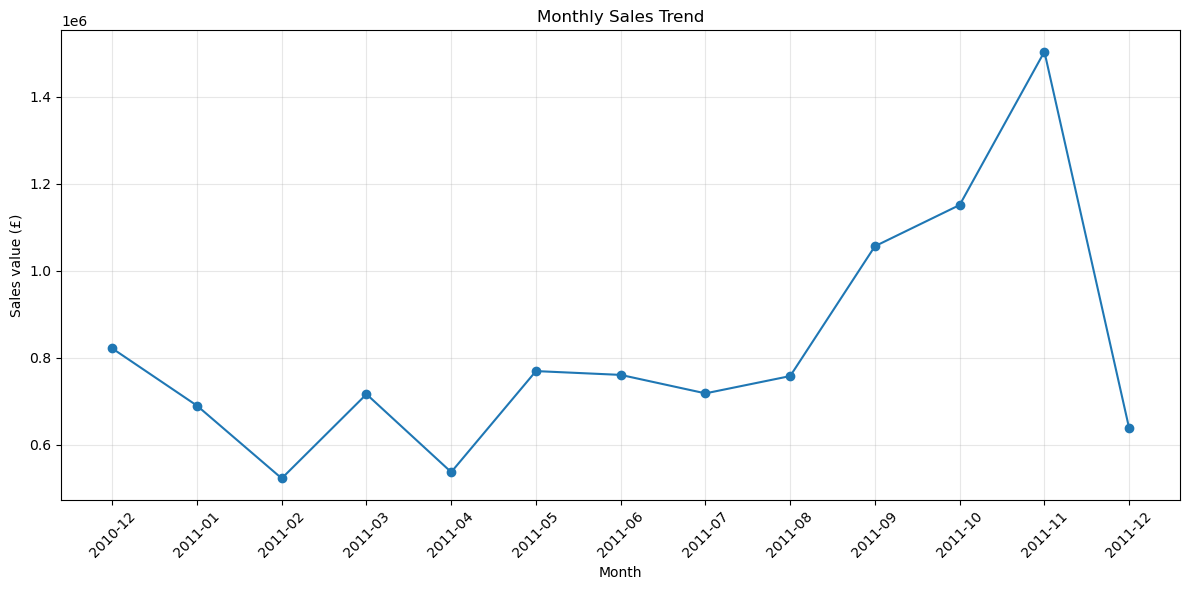

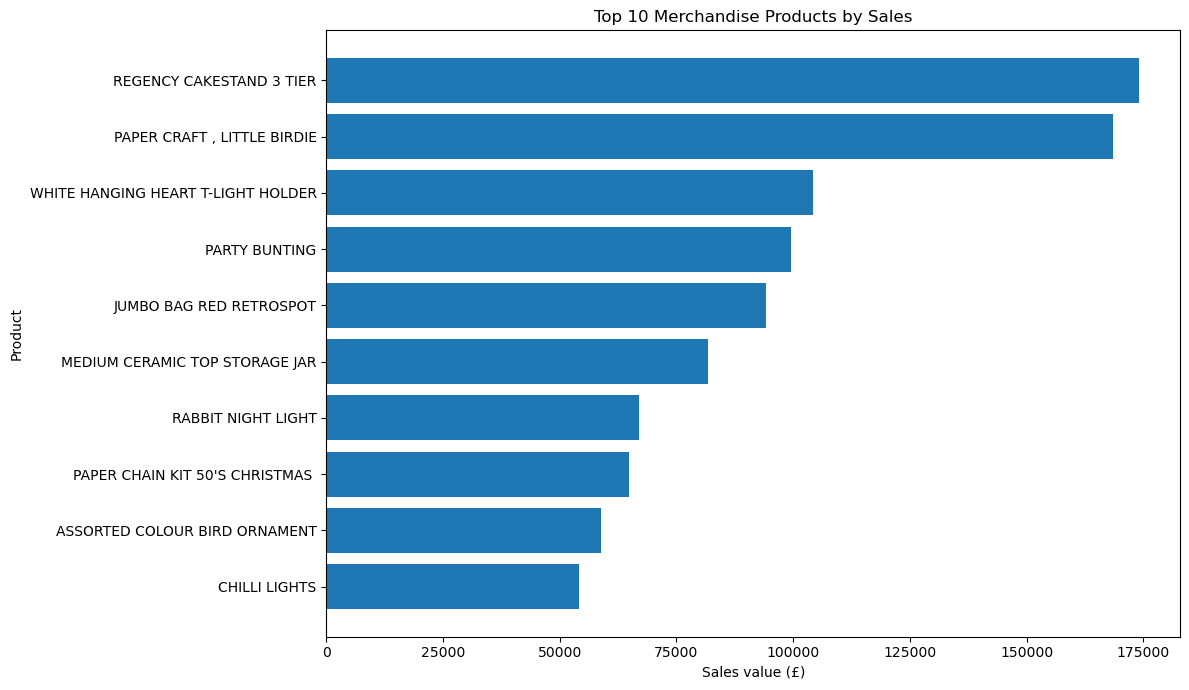

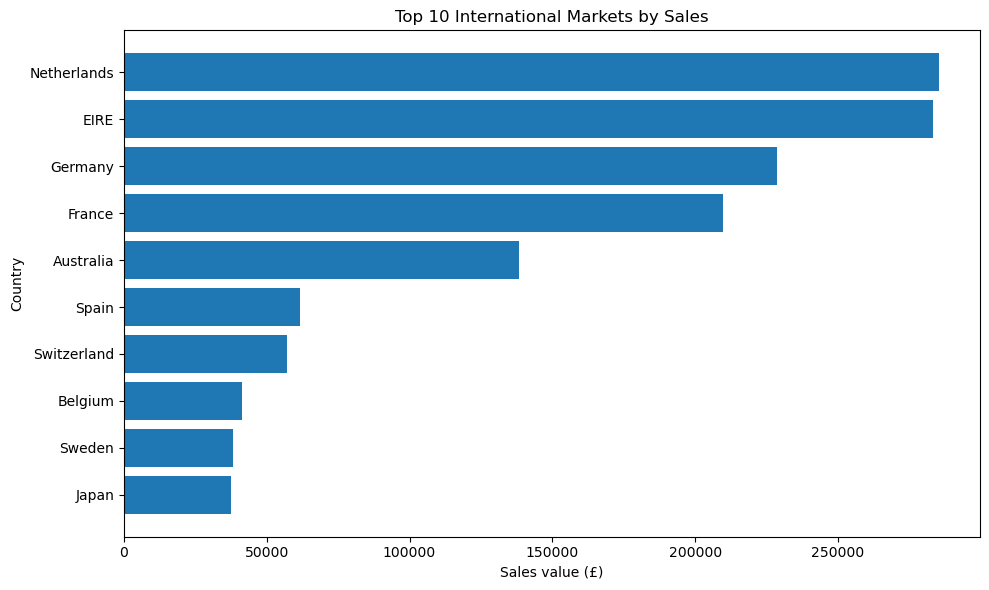


Charts saved to:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/dashboard/charts
- international_sales_by_country.png (64,225 bytes)
- monthly_sales_trend.png (109,571 bytes)
- top_merchandise_products.png (113,452 bytes)


In [36]:

# STEP 9: Create and save portfolio charts

import matplotlib.pyplot as plt
from pathlib import Path

project_path = file_path.parents[2]
charts_path = project_path / "dashboard" / "charts"
charts_path.mkdir(parents=True, exist_ok=True)

# Chart 1: Monthly sales trend
monthly_chart_data = (
    df_clean.assign(
        Month=df_clean["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month", as_index=False)
    .agg(Sales=("Revenue", "sum"))
    .sort_values("Month")
)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(
    monthly_chart_data["Month"],
    monthly_chart_data["Sales"],
    marker="o"
)
ax.set_title("Monthly Sales Trend")
ax.set_xlabel("Month")
ax.set_ylabel("Sales value (£)")
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(
    charts_path / "monthly_sales_trend.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Chart 2: Top 10 merchandise products by sales
# Use the top_merchandise table created in Step 8.
products_chart_data = top_merchandise.sort_values("Sales")

fig, ax = plt.subplots(figsize=(12, 7))
ax.barh(
    products_chart_data["Description"],
    products_chart_data["Sales"]
)
ax.set_title("Top 10 Merchandise Products by Sales")
ax.set_xlabel("Sales value (£)")
ax.set_ylabel("Product")
fig.tight_layout()
fig.savefig(
    charts_path / "top_merchandise_products.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Chart 3: Top international markets, excluding the UK
# The UK is shown separately because its sales are much higher
# and would make comparisons between other countries difficult.
international_sales = (
    country_performance[
        country_performance["Country"] != "United Kingdom"
    ]
    .sort_values("Sales", ascending=False)
    .head(10)
    .sort_values("Sales")
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(
    international_sales["Country"],
    international_sales["Sales"]
)
ax.set_title("Top 10 International Markets by Sales")
ax.set_xlabel("Sales value (£)")
ax.set_ylabel("Country")
fig.tight_layout()
fig.savefig(
    charts_path / "international_sales_by_country.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

print("\nCharts saved to:")
print(charts_path)
for chart_file in sorted(charts_path.glob("*.png")):
    print(f"- {chart_file.name} ({chart_file.stat().st_size:,} bytes)")


In [38]:

from pathlib import Path

project_path = file_path.parents[1]
reports_path = project_path / "reports"
reports_path.mkdir(parents=True, exist_ok=True)

# Overall business performance
total_sales = df_clean["Revenue"].sum()
total_quantity = df_clean["Quantity"].sum()
total_invoices = df_clean["InvoiceNo"].nunique()
average_order_value = total_sales / total_invoices

# Monthly performance
monthly_report = (
    df_clean.assign(
        Month=df_clean["InvoiceDate"].dt.to_period("M").astype(str)
    )
    .groupby("Month", as_index=False)
    .agg(Sales=("Revenue", "sum"), Invoices=("InvoiceNo", "nunique"))
    .sort_values("Sales", ascending=False)
)

best_month = monthly_report.iloc[0]

# Product performance
top_product = top_merchandise.sort_values(
    "Sales", ascending=False
).iloc[0]

# International markets, excluding the UK
international_report = (
    country_performance[
        country_performance["Country"] != "United Kingdom"
    ]
    .sort_values("Sales", ascending=False)
)

top_international = international_report.iloc[0]

# Data-quality context
missing_customer_pct = (
    df_clean["CustomerID"].isna().mean() * 100
)

report = f"""
ONLINE RETAIL BUSINESS ANALYSIS
Business Insights Report

1. PROJECT OVERVIEW

This project analyses online retail transaction data from December 2010
to December 2011. The objective is to understand sales performance,
product performance, and international markets using Python and pandas.

2. DATA PREPARATION

The original dataset contained {len(df):,} rows.
The cleaned analytical dataset contains {len(df_clean):,} rows.

The preparation process removed exact duplicate rows, cancelled invoices,
non-positive quantities, and non-positive unit prices. A Revenue column
was calculated as Quantity multiplied by UnitPrice.

These are analytical cleaning rules. Excluded records may include returns,
adjustments, or other non-standard transactions.

3. OVERALL BUSINESS PERFORMANCE

Total sales value: £{total_sales:,.2f}
Total quantity sold: {total_quantity:,}
Unique invoices: {total_invoices:,}
Average sales value per invoice: £{average_order_value:,.2f}

Sales value represents transaction revenue in the cleaned dataset.
It should not be interpreted as profit.

4. MONTHLY SALES PERFORMANCE

The highest-sales month in the dataset was {best_month['Month']},
with sales of £{best_month['Sales']:,.2f} across
{int(best_month['Invoices']):,} invoices.

November 2011 was the strongest full month by sales.
December 2011 is incomplete because the dataset ends on 9 December 2011,
so it should not be compared directly with full months.

5. PRODUCT PERFORMANCE

The leading product in the merchandise ranking was
{top_product['Description']}, with recorded sales of
£{top_product['Sales']:,.2f}.

Product rankings should be interpreted carefully. Some stock codes
may represent postage, manual entries, or other special charges rather
than ordinary merchandise.

The product "PAPER CRAFT , LITTLE BIRDIE" recorded an unusually large
quantity in a single transaction. This record was retained but flagged
for further investigation rather than assumed to be an error.

6. INTERNATIONAL MARKETS

The leading market outside the United Kingdom was
{top_international['Country']}, with sales of
£{top_international['Sales']:,.2f}.

The United Kingdom accounts for approximately 84.6% of cleaned sales
value, indicating that sales in this dataset are heavily concentrated
in the domestic market.

7. DATA LIMITATIONS

- CustomerID is missing from approximately {missing_customer_pct:.2f}%
  of the cleaned transaction rows. Customer-level findings may therefore
  be incomplete.
- The dataset covers a limited period and should not be treated as
  evidence of current retail performance.
- The analysis excludes cancelled invoices and non-positive transaction
  quantities and prices.
- Sales value is not the same as profit because product costs and other
  operating expenses are not available.
- Unusual records require business validation before any operational
  decisions are made.

8. CONCLUSION

The analysis establishes a baseline view of sales, invoice activity,
product performance, and international markets. The strongest next steps
are to investigate unusual transactions, assess customer data coverage,
and build an interactive dashboard to make the findings easier to explore.

Report generated from the cleaned analytical dataset.
"""

report_path = reports_path / "business_insights_report.txt"
report_path.write_text(report.strip(), encoding="utf-8")

print("Business insights report saved successfully:")
print(report_path)
print("\nReport preview:\n")
print(report)


Business insights report saved successfully:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/reports/business_insights_report.txt

Report preview:


ONLINE RETAIL BUSINESS ANALYSIS
Business Insights Report

1. PROJECT OVERVIEW

This project analyses online retail transaction data from December 2010
to December 2011. The objective is to understand sales performance,
product performance, and international markets using Python and pandas.

2. DATA PREPARATION

The original dataset contained 541,909 rows.
The cleaned analytical dataset contains 524,878 rows.

The preparation process removed exact duplicate rows, cancelled invoices,
non-positive quantities, and non-positive unit prices. A Revenue column
was calculated as Quantity multiplied by UnitPrice.

These are analytical cleaning rules. Excluded records may include returns,
adjustments, or other non-standard transactions.

3. OVERALL BUSINESS PERFORMANCE

Total sales value: £10,642,110.80
Total quantity s

In [40]:

from pathlib import Path

project_path = file_path.parents[1]
readme_path = project_path / "README.md"

readme_content = """# Online Retail Business Analytics

## Project Overview

This project analyses historical online retail transactions to understand
sales performance, product performance, and international markets.

Python and pandas were used to inspect, clean, analyse, and summarise the data.
The project also includes visualisations and a written business insights report.

## Business Questions

- What does overall sales performance look like?
- How does sales value change from month to month?
- Which merchandise products generate the highest recorded sales?
- Which international markets generate the highest sales value?
- What data-quality issues should be considered when interpreting the results?

## Dataset

The dataset contains historical transactions from an online retailer,
covering 1 December 2010 to 9 December 2011.

The original dataset contains 541,909 rows and eight columns.

The analysis uses the following fields:

- InvoiceNo
- StockCode
- Description
- Quantity
- InvoiceDate
- UnitPrice
- CustomerID
- Country

## Tools Used

- Python
- pandas
- Matplotlib
- Jupyter Notebook

## Data Preparation

The preparation process included:

1. Inspecting the dataset and checking missing values.
2. Removing 5,268 exact duplicate rows.
3. Excluding invoices whose invoice number begins with `C`.
4. Excluding transactions with non-positive quantities.
5. Excluding transactions with non-positive unit prices.
6. Creating a `Revenue` field using `Quantity * UnitPrice`.
7. Retaining missing customer IDs for overall sales analysis.

The resulting analytical dataset contains 524,878 rows.

These are analytical filtering decisions, not proof that every excluded
record was invalid. Excluded records may include returns, adjustments,
or other non-standard transactions.

## Key Findings

- Total sales value in the cleaned dataset: £10,642,110.80.
- Total quantity sold: 5,572,420.
- Unique invoices: 19,960.
- Average sales value per invoice: £533.17.
- November 2011 was the strongest full month by sales value, at £1,503,866.78.
- The United Kingdom accounted for approximately 84.6% of cleaned sales value.
- The Netherlands was the highest-sales market outside the United Kingdom,
  with £285,446.34 in recorded sales.

The average sales value per invoice is calculated by dividing total sales
value by the number of unique invoices. Sales value is not profit.

## Visualisations

The project includes three charts:

- Monthly sales trend
- Top merchandise products by sales
- Top international markets by sales

## Limitations

- Approximately 25.18% of rows in the cleaned dataset have no CustomerID.
- December 2011 is incomplete because the data ends on 9 December.
- The data is historical and does not represent current retail performance.
- Product costs and operating expenses are unavailable, so profit cannot be calculated.
- An unusually large single transaction for `PAPER CRAFT , LITTLE BIRDIE`
  was retained and flagged for further investigation.
- Some stock codes may represent postage, manual entries, or special charges.
- Customer-level analysis may be incomplete because of missing customer identifiers.

## Project Structure

```text
01_Ecommerce_Analytics/
├── data/
│   ├── raw/
│   └── processed/
├── notebooks/
├── reports/
└── dashboard/
    └── charts/
```

The original raw dataset should remain unchanged. Processed files and reports
are generated separately.

## Reproducibility

The analysis was conducted in a Jupyter Notebook using Python, pandas,
and Matplotlib. The cleaning rules and limitations are documented so that
the results can be interpreted and reviewed.

## Currency Note

Values are presented in pounds sterling (£), consistent with the UK retail
context of the dataset. This assumption should be verified against the
dataset documentation before formal reporting.
"""

readme_path.write_text(readme_content, encoding="utf-8")

print("README created successfully:")
print(readme_path)
print("\nFile size:", f"{readme_path.stat().st_size:,}", "bytes")


README created successfully:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/README.md

File size: 3,873 bytes


In [42]:

from pathlib import Path
import shutil

# Locate the project folder
project_path = file_path.parents[1]

# Current and correct chart folders
old_charts_path = project_path.parent / "dashboard" / "charts"
new_charts_path = project_path / "dashboard" / "charts"

new_charts_path.mkdir(parents=True, exist_ok=True)

# Move the charts if they exist in the old folder
chart_names = [
    "monthly_sales_trend.png",
    "top_merchandise_products.png",
    "international_sales_by_country.png"
]

for chart_name in chart_names:
    old_chart = old_charts_path / chart_name
    new_chart = new_charts_path / chart_name

    if old_chart.exists():
        shutil.move(str(old_chart), str(new_chart))
        print(f"Moved: {chart_name}")
    elif new_chart.exists():
        print(f"Already in project folder: {chart_name}")
    else:
        print(f"Not found: {chart_name}")

print("\nCorrect project chart folder:")
print(new_charts_path)


Moved: monthly_sales_trend.png
Moved: top_merchandise_products.png
Moved: international_sales_by_country.png

Correct project chart folder:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/dashboard/charts


In [44]:

from pathlib import Path

project_path = file_path.parents[1]

for item in sorted(project_path.rglob("*")):
    if item.is_file():
        relative_path = item.relative_to(project_path)
        print(f"FILE   {relative_path}")
    elif item.is_dir():
        relative_path = item.relative_to(project_path)
        print(f"FOLDER {relative_path}/")


FILE   .DS_Store
FOLDER .ipynb_checkpoints/
FILE   README.md
FOLDER dashboard/
FOLDER dashboard/charts/
FILE   dashboard/charts/international_sales_by_country.png
FILE   dashboard/charts/monthly_sales_trend.png
FILE   dashboard/charts/top_merchandise_products.png
FOLDER notebooks/
FOLDER notebooks/.ipynb_checkpoints/
FILE   notebooks/.ipynb_checkpoints/01_Online_Retail_Data_Inspection-checkpoint.ipynb
FILE   notebooks/01_Online_Retail_Data_Inspection.ipynb
FOLDER processed/
FOLDER raw/
FILE   raw/Online Retail.xlsx
FOLDER reports/
FILE   reports/business_insights_report.txt
FOLDER screenshots/
FOLDER sql/


In [46]:

from pathlib import Path

project_path = file_path.parents[1]

folders_to_check = {
    "Processed data": project_path / "processed",
    "Reports": project_path / "reports",
    "Raw data": project_path / "raw",
    "Charts": project_path / "dashboard" / "charts"
}

for folder_name, folder_path in folders_to_check.items():
    print(f"\n{folder_name}:")
    print(f"Location: {folder_path}")

    if not folder_path.exists():
        print("  Folder does not exist.")
        continue

    files_found = [
        item for item in folder_path.iterdir()
        if item.is_file()
    ]

    if files_found:
        for item in sorted(files_found):
            print(f"  {item.name} ({item.stat().st_size:,} bytes)")
    else:
        print("  No files found directly in this folder.")



Processed data:
Location: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/processed
  No files found directly in this folder.

Reports:
Location: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/reports
  business_insights_report.txt (3,049 bytes)

Raw data:
Location: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/raw
  Online Retail.xlsx (23,715,344 bytes)

Charts:
Location: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/dashboard/charts
  international_sales_by_country.png (64,225 bytes)
  monthly_sales_trend.png (109,571 bytes)
  top_merchandise_products.png (113,452 bytes)


In [48]:

from pathlib import Path

portfolio_root = file_path.parents[2]

files_to_find = [
    "online_retail_cleaned.csv",
    "cleaning_summary.csv",
    "data_cleaning_report.txt",
    "monthly_sales_trend.csv",
    "core_business_kpis.csv"
]

print("Searching portfolio folder:")
print(portfolio_root)

for filename in files_to_find:
    matches = list(portfolio_root.rglob(filename))

    print(f"\n{filename}:")
    if matches:
        for match in matches:
            print(f"  Found: {match}")
    else:
        print("  Not found")


Searching portfolio folder:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio

online_retail_cleaned.csv:
  Found: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/data/processed/online_retail_cleaned.csv

cleaning_summary.csv:
  Found: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/cleaning_summary.csv

data_cleaning_report.txt:
  Found: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/data_cleaning_report.txt

monthly_sales_trend.csv:
  Found: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/monthly_sales_trend.csv

core_business_kpis.csv:
  Found: /Users/muntahashah/Desktop/Business-Analytics-Portfolio/reports/core_business_kpis.csv


In [50]:

from pathlib import Path
import shutil

portfolio_root = file_path.parents[2]
project_path = file_path.parents[1]

# Source and destination folders
source_processed = portfolio_root / "data" / "processed"
source_reports = portfolio_root / "reports"

destination_processed = project_path / "processed"
destination_reports = project_path / "reports"

destination_processed.mkdir(parents=True, exist_ok=True)
destination_reports.mkdir(parents=True, exist_ok=True)

# Copy the cleaned dataset
files_to_copy = [
    (
        source_processed / "online_retail_cleaned.csv",
        destination_processed / "online_retail_cleaned.csv"
    )
]

# Copy reports and summary tables
report_names = [
    "cleaning_summary.csv",
    "data_cleaning_report.txt",
    "monthly_sales_trend.csv",
    "core_business_kpis.csv"
]

for name in report_names:
    files_to_copy.append(
        (source_reports / name, destination_reports / name)
    )

# Copy files, checking that each source exists
for source, destination in files_to_copy:
    if source.exists():
        shutil.copy2(source, destination)
        print(f"Copied: {source.name}")
    else:
        print(f"SOURCE NOT FOUND: {source}")

print("\nCopy operation finished.")


Copied: online_retail_cleaned.csv
Copied: cleaning_summary.csv
Copied: data_cleaning_report.txt
Copied: monthly_sales_trend.csv
Copied: core_business_kpis.csv

Copy operation finished.


In [52]:

from pathlib import Path

project_path = file_path.parents[1]

folders_to_verify = [
    project_path / "processed",
    project_path / "reports"
]

for folder in folders_to_verify:
    print(f"\n{folder.relative_to(project_path)}/")

    for item in sorted(folder.iterdir()):
        if item.is_file():
            print(f"  {item.name} ({item.stat().st_size:,} bytes)")



processed/
  online_retail_cleaned.csv (49,553,474 bytes)

reports/
  business_insights_report.txt (3,049 bytes)
  cleaning_summary.csv (250 bytes)
  core_business_kpis.csv (210 bytes)
  data_cleaning_report.txt (1,910 bytes)
  monthly_sales_trend.csv (432 bytes)


In [54]:

from pathlib import Path

project_path = file_path.parents[1]
gitignore_path = project_path / ".gitignore"

gitignore_content = """# Original raw data
raw/
*.xlsx

# Jupyter temporary files
.ipynb_checkpoints/
**/.ipynb_checkpoints/

# macOS system files
.DS_Store
**/.DS_Store

# Python cache files
__pycache__/
*.py[cod]

# Virtual environments
.venv/
venv/

# Temporary files
*.tmp
*.log
"""

gitignore_path.write_text(gitignore_content, encoding="utf-8")

print(".gitignore created successfully:")
print(gitignore_path)
print("\nContents:\n")
print(gitignore_path.read_text(encoding="utf-8"))


.gitignore created successfully:
/Users/muntahashah/Desktop/Business-Analytics-Portfolio/01_Ecommerce_Analytics/.gitignore

Contents:

# Original raw data
raw/
*.xlsx

# Jupyter temporary files
.ipynb_checkpoints/
**/.ipynb_checkpoints/

# macOS system files
.DS_Store
**/.DS_Store

# Python cache files
__pycache__/
*.py[cod]

# Virtual environments
.venv/
venv/

# Temporary files
*.tmp
*.log



In [56]:

from pathlib import Path

project_path = file_path.parents[1]

important_files = [
    "README.md",
    ".gitignore",
    "notebooks/01_Online_Retail_Data_Inspection.ipynb",
    "processed/online_retail_cleaned.csv",
    "reports/cleaning_summary.csv",
    "reports/data_cleaning_report.txt",
    "reports/monthly_sales_trend.csv",
    "reports/core_business_kpis.csv",
    "reports/business_insights_report.txt",
    "dashboard/charts/monthly_sales_trend.png",
    "dashboard/charts/top_merchandise_products.png",
    "dashboard/charts/international_sales_by_country.png",
]

print("PROJECT FILE CHECK\n")

all_present = True

for relative_name in important_files:
    item = project_path / relative_name
    exists = item.is_file()

    print(f"{'OK' if exists else 'MISSING'}: {relative_name}")

    if not exists:
        all_present = False

print("\nAll listed files present:", all_present)


PROJECT FILE CHECK

OK: README.md
OK: .gitignore
OK: notebooks/01_Online_Retail_Data_Inspection.ipynb
OK: processed/online_retail_cleaned.csv
OK: reports/cleaning_summary.csv
OK: reports/data_cleaning_report.txt
OK: reports/monthly_sales_trend.csv
OK: reports/core_business_kpis.csv
OK: reports/business_insights_report.txt
OK: dashboard/charts/monthly_sales_trend.png
OK: dashboard/charts/top_merchandise_products.png
OK: dashboard/charts/international_sales_by_country.png

All listed files present: True
